# AIE322 – Advanced Machine Learning
## E-Commerce Customer Churn Classification

**Student:** Marwan Soliman  |  **Faculty of Computer Science & Engineering, New Mansoura University**

**Goal:** predict whether a customer will churn (`Churn` = 1) or stay (`Churn` = 0) using a leakage-free scikit-learn pipeline, and use the project to practise the main ideas from the course: pipelines, bias-variance, regularization and ensembles.

**Plan of the notebook**
1. Cleaning, EDA and a reproducible split
2. Preprocessing pipelines (`ColumnTransformer` + `Pipeline`)
3. Bias-variance and regularization (Logistic Regression with L1 / L2 / Elastic Net)
4. Ensembles: Bagging vs Pasting, AdaBoost, Voting
5. Final comparison and conclusions

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier,
                              RandomForestClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

---
# Part 1: Data Cleaning, EDA & Reproducible Splitting
### 1.1 Loading the data
I wrote a small loader that looks for the Kaggle file in the usual places (the xlsx has a sheet called `E Comm`, but a csv version works too). If it can't find the file, change `DATA_PATH` manually.

In [ ]:
DATA_PATH = r"C:\Users\solim\Downloads\assinment1\E Commerce Dataset.xlsx"

def load_data(path=None):
    """Find and load the e-commerce churn file (xlsx or csv)."""
    if path is None:
        names = ["E Commerce Dataset.xlsx", "E_Commerce_Dataset.xlsx",
                 "E Commerce Dataset.csv", "ecommerce_churn.csv"]
        folders = [Path("."), Path("data"), Path("/kaggle/input"), Path("/content")]
        for folder in folders:
            for n in names:
                hits = list(folder.rglob(n)) if folder.exists() else []
                if hits:
                    path = hits[0]
                    break
            if path:
                break
    if path is None:
        raise FileNotFoundError("Dataset not found - set DATA_PATH to the file location.")

    path = Path(path)
    print("Loading:", path)

    with open(path, "rb") as f:
        is_excel = f.read(2) == b"PK"

    if is_excel:
        try:
            return pd.read_excel(path, sheet_name="E Comm", engine="openpyxl")
        except ValueError:
            return pd.read_excel(path, engine="openpyxl")

    for enc in ("utf-8", "utf-8-sig", "latin-1", "cp1252"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("Could not read the file with the common encodings.")

df_raw = load_data(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Loading: C:\Users\solim\Downloads\assinment1\E Commerce Dataset.xlsx
Shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [ ]:
df_raw.info()
print()
print("Missing values per column:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

### 1.2 Cleaning
Steps:
- drop `CustomerID` (it's just an identifier, it carries no behaviour)
- check duplicates (I drop them **before** splitting, otherwise the same row could land in both train and test and inflate the score)
- unify a few category labels that mean the same thing (`Phone` / `Mobile Phone`, `CC` / `Credit Card`, `COD` / `Cash on Delivery`)
- look at outliers with the IQR rule

In [ ]:
df = df_raw.drop(columns=["CustomerID"], errors="ignore").copy()

# duplicates
n_dup = df.duplicated().sum()
print(f"Duplicate rows (without CustomerID): {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

# same meaning, different spelling
relabel = {
    "PreferredLoginDevice": {"Phone": "Mobile Phone"},
    "PreferredPaymentMode": {"CC": "Credit Card", "COD": "Cash on Delivery"},
    "PreferedOrderCat":     {"Mobile": "Mobile Phone"},
}
for col, mapping in relabel.items():
    if col in df.columns:
        df[col] = df[col].replace(mapping)

for col in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]:
    print(f"\n{col}: {df[col].unique().tolist()}")

Duplicate rows (without CustomerID): 556
Shape after dropping duplicates: (5074, 19)

PreferredLoginDevice: ['Mobile Phone', 'Computer']

PreferredPaymentMode: ['Debit Card', 'UPI', 'Credit Card', 'Cash on Delivery', 'E wallet']

Gender: ['Female', 'Male']

PreferedOrderCat: ['Laptop & Accessory', 'Mobile Phone', 'Others', 'Fashion', 'Grocery']

MaritalStatus: ['Single', 'Divorced', 'Married']


In [ ]:
canonical = ["CustomerID", "Churn", "Tenure", "PreferredLoginDevice", "CityTier",
             "WarehouseToHome", "PreferredPaymentMode", "Gender", "HourSpendOnApp",
             "NumberOfDeviceRegistered", "PreferedOrderCat", "SatisfactionScore",
             "MaritalStatus", "NumberOfAddress", "Complain",
             "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount",
             "DaySinceLastOrder", "CashbackAmount"]

def norm(s):
    return str(s).strip().lower().replace("_", "").replace(" ", "")

lookup = {norm(c): c for c in canonical}
df_raw.columns = [lookup.get(norm(c), str(c).strip()) for c in df_raw.columns]

print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())

missing = [c for c in canonical if c not in df_raw.columns]
extra = [c for c in df_raw.columns if c not in canonical]
print("\nMissing columns:", missing)
print("Extra columns  :", extra)

if "Churn" not in df_raw.columns:
    raise KeyError("No Churn column found - check the printed column list above.")

Shape: (5630, 20)
Columns: ['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Missing columns: []
Extra columns  : []


**Observation:** a few columns (like `WarehouseToHome`, `CashbackAmount`, `OrderCount`) have some points outside the IQR fences, but they look like genuine customers (far-away warehouses, heavy buyers). I keep them. The only thing to remember is that `MinMaxScaler` is sensitive to extreme values, so those columns will have most of their data squeezed into a narrow range after scaling.

### 1.3 Exploratory Data Analysis

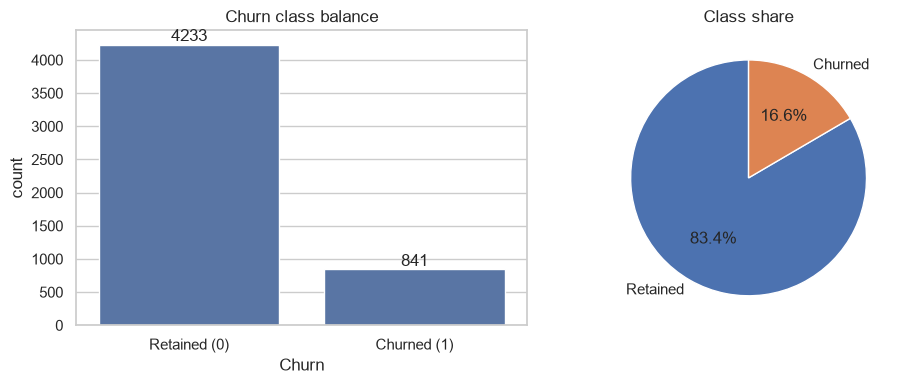

Churn rate: 16.57%


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = df["Churn"].value_counts().sort_index()
sns.countplot(x="Churn", data=df, ax=ax[0])
ax[0].set_title("Churn class balance")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Retained (0)", "Churned (1)"])
for i, v in enumerate(counts):
    ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[1].pie(counts, labels=["Retained", "Churned"], autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()
print("Churn rate: %.2f%%" % (100 * df['Churn'].mean()))

The data is **imbalanced** (roughly 1 churner for every 5 retained customers). So accuracy alone is misleading: a model that predicts "nobody churns" would already get about 83%. That's why I report Precision, Recall and F1 next to accuracy for every model.

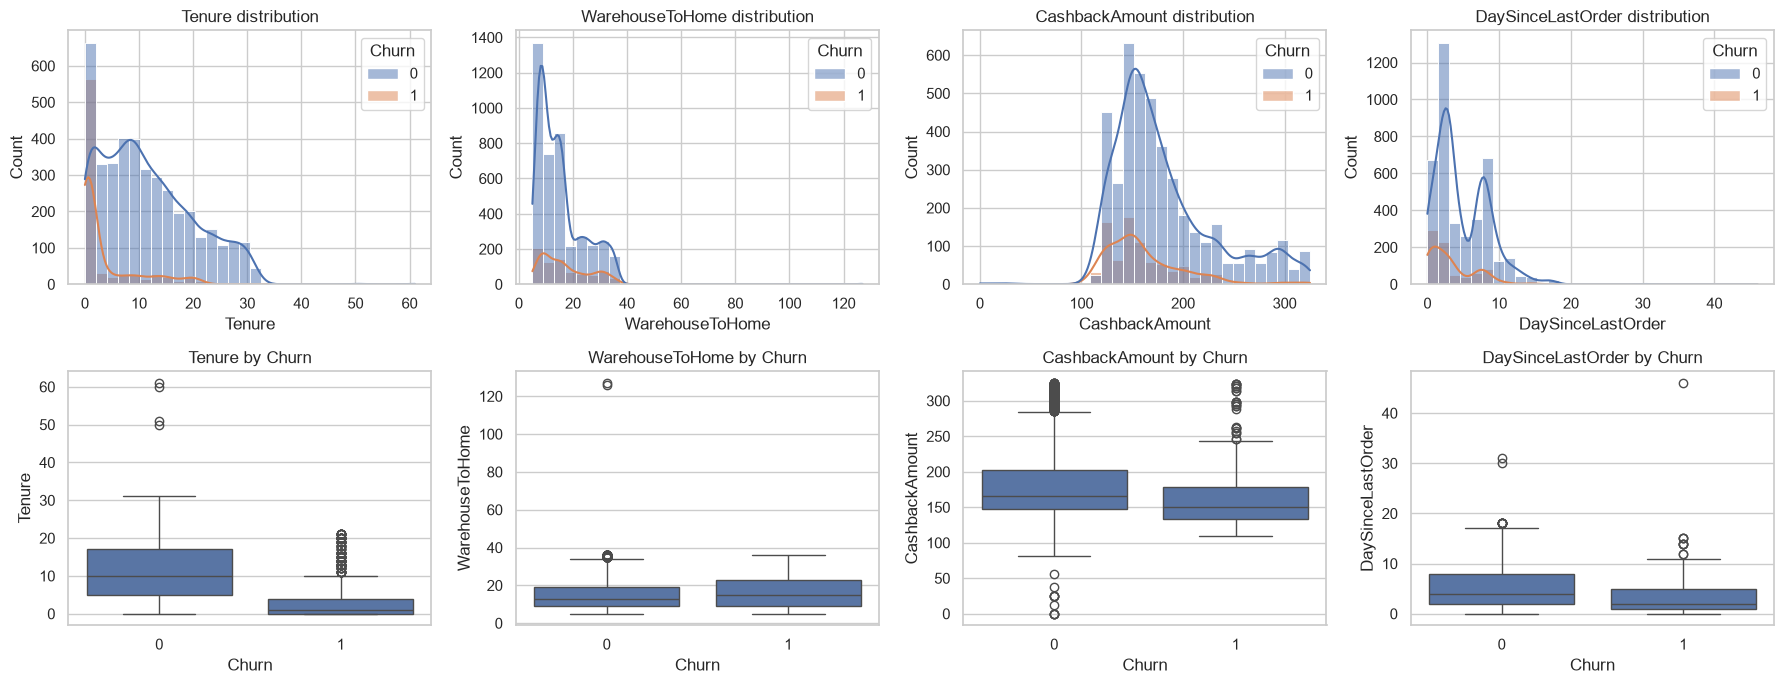

In [ ]:
key_num = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(key_num):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"{c} distribution")
    sns.boxplot(data=df, x="Churn", y=c, ax=axes[1, i])
    axes[1, i].set_title(f"{c} by Churn")
plt.tight_layout(); plt.show()

**What I notice:** churners tend to have a much **shorter tenure** (new customers leave more), and `DaySinceLastOrder` / `CashbackAmount` also look different between the two groups. `WarehouseToHome` has a long right tail (the outliers from before).

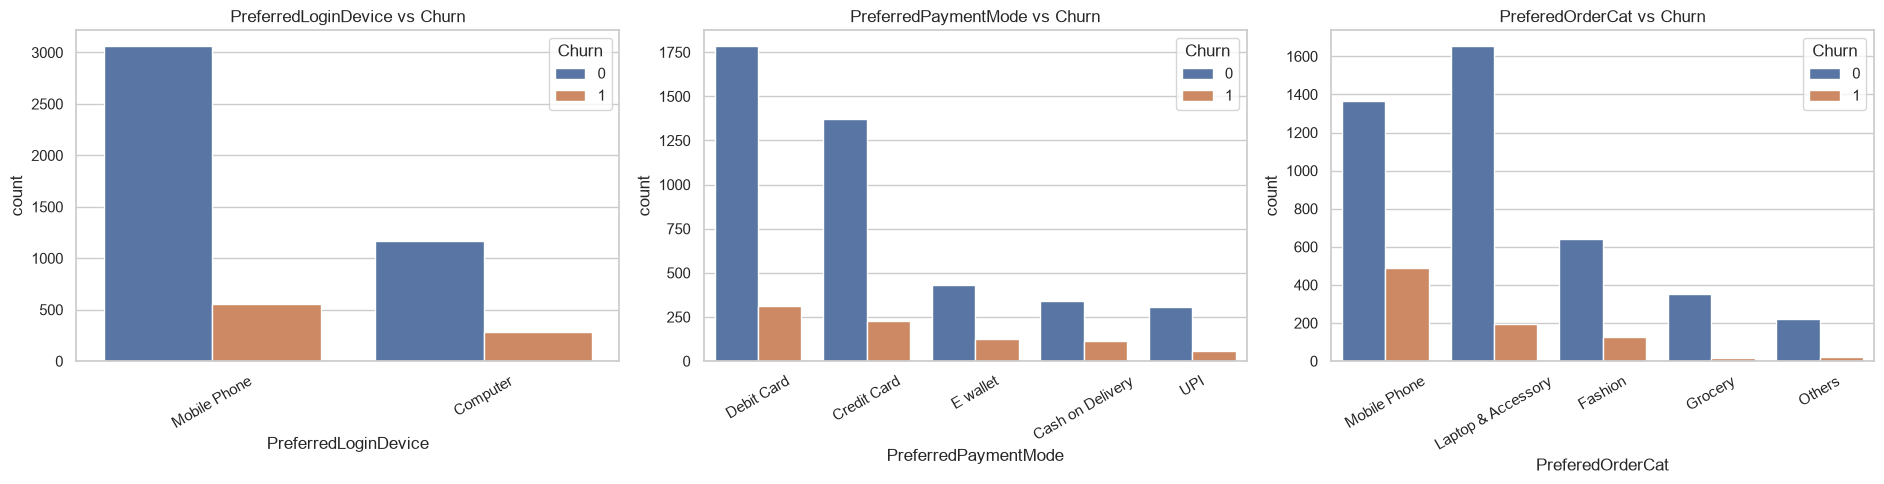

PreferredLoginDevice
Computer        19.6
Mobile Phone    15.4 

PreferredPaymentMode
Cash on Delivery    25.4
E wallet            22.8
UPI                 15.6
Debit Card          15.0
Credit Card         14.2 

PreferedOrderCat
Mobile Phone          26.3
Fashion               16.3
Laptop & Accessory    10.5
Others                 7.9
Grocery                4.4 



In [ ]:
key_cat = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, c in zip(axes, key_cat):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, hue="Churn", order=order, ax=ax)
    ax.set_title(f"{c} vs Churn")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# churn *rate* per category is easier to compare than raw counts
for c in key_cat:
    print((df.groupby(c)["Churn"].mean().sort_values(ascending=False) * 100).round(1).to_string(), "\n")

### 1.4 Reproducible train/test split
Stratified 80/20 split so both sets keep the same churn ratio.

In [ ]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (4059, 18) | Test: (1015, 18)
Churn rate train: 0.166 | test: 0.166


**Analytical Question – Why is `random_state` essential when splitting?**

`train_test_split` shuffles the rows randomly before cutting them, so without a fixed seed every run gives a different train/test set. Then:
- the results are **not reproducible**: I (or the instructor) could run the same notebook and get different scores;
- I can't tell whether a change in the score comes from my model or just from a lucky/unlucky split;
- comparing two models is unfair if each was evaluated on a different test set.

Setting `random_state=42` fixes the random number generator, so the same rows go to train and test every time. Together with `stratify=y` this gives a split that is both reproducible and representative.

---
# Part 2: Preprocessing Pipelines
### 2.1 Numerical and categorical columns
`CityTier`, `Complain` and `SatisfactionScore` are stored as numbers (ordinal or 0/1), so I leave them in the numerical group.

In [ ]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print("Numerical (%d):" % len(num_cols), num_cols)
print("Categorical (%d):" % len(cat_cols), cat_cols)

Numerical (13): ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical (5): ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [ ]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

### 2.2 Inspecting `SimpleImputer`: `.statistics_`

In [ ]:
imp = SimpleImputer(strategy="median")
imp.fit(X_train[num_cols])

learned = pd.Series(imp.statistics_, index=num_cols, name="median (learned on train)")
print(learned.round(3).to_string())

# what happens if we try the 'obvious' attribute name?
print("\nhasattr(imp, 'statistics_'):", hasattr(imp, "statistics_"))
print("hasattr(imp, 'median_')    :", hasattr(imp, "median_"))

Tenure                           9.00
CityTier                         1.00
WarehouseToHome                 13.00
HourSpendOnApp                   3.00
NumberOfDeviceRegistered         4.00
SatisfactionScore                3.00
NumberOfAddress                  3.00
Complain                         0.00
OrderAmountHikeFromlastYear     15.00
CouponUsed                       1.00
OrderCount                       2.00
DaySinceLastOrder                3.00
CashbackAmount                 163.49

hasattr(imp, 'statistics_'): True
hasattr(imp, 'median_')    : False


**Why `.statistics_` and not `.median_`?**
`SimpleImputer` supports several strategies: `"mean"`, `"median"`, `"most_frequent"` and `"constant"`. Whatever the strategy is, the fitted fill value for each column is stored in the **same** attribute, `statistics_`. That keeps the API consistent (code that reads the learned values doesn't have to change when you change the strategy), and `median_` or `mean_` simply don't exist on the object, as the `hasattr` check above shows. Also, these values are computed on the **training data only**, and reused later on the test set, which is what keeps the pipeline leakage-free.

### 2.3 Inspecting `OneHotEncoder` output (sparse matrix)

In [ ]:
ohe = OneHotEncoder()
encoded = ohe.fit_transform(X_train[cat_cols])

print("type(encoded)      :", type(encoded))
print("shape              :", encoded.shape)
print("stored (non-zero)  :", encoded.nnz, "of", encoded.shape[0] * encoded.shape[1], "cells")
print("density            : %.1f%%" % (100 * encoded.nnz / (encoded.shape[0] * encoded.shape[1])))
print("\nCategories learned:")
for c, cats in zip(cat_cols, ohe.categories_):
    print(f"  {c}: {list(cats)}")

type(encoded)      : <class 'scipy.sparse._csr.csr_matrix'>
shape              : (4059, 17)
stored (non-zero)  : 20295 of 69003 cells
density            : 29.4%

Categories learned:
  PreferredLoginDevice: ['Computer', 'Mobile Phone']
  PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
  Gender: ['Female', 'Male']
  PreferedOrderCat: ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
  MaritalStatus: ['Divorced', 'Married', 'Single']


**Why does scikit-learn return a sparse matrix by default?**
One-hot encoding turns each category into its own 0/1 column, and every row has exactly **one** `1` per original feature and zeros everywhere else. So the result is mostly zeros. A `scipy.sparse` matrix only stores the non-zero values and their positions, which saves a lot of memory (and speeds up many operations) compared with a dense NumPy array that stores every zero. With high-cardinality columns (hundreds of categories) the dense version could simply not fit in RAM. In this dataset the categories are few, so the saving is small, but the default is designed for the general case. If a model needs dense input, you can use `sparse_output=False` or `.toarray()`.

### 2.4 `ColumnTransformer` + master `Pipeline`

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ],
    sparse_threshold=0,   # always return a dense array so every model below can use it
)

master_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
])

master_pipe.fit(X_train, y_train)
print("Train accuracy: %.4f" % master_pipe.score(X_train, y_train))
print("Test accuracy : %.4f" % master_pipe.score(X_test, y_test))
print("Features after preprocessing:", master_pipe.named_steps["prep"].transform(X_train).shape[1])

Train accuracy: 0.8921
Test accuracy : 0.8847
Features after preprocessing: 30


**Execution Flow Question – what happens inside `pipeline.fit(X_train, y_train)`?**

The pipeline goes through its steps in order:

1. **Transformers** (here the `ColumnTransformer`, and inside it the imputers, scaler and encoder): for each one scikit-learn calls `fit_transform(X, y)`. So the medians, the min/max values and the category lists are **learned from X_train**, and the data is transformed immediately. The output of one step becomes the input of the next step.
2. **Final estimator** (the classifier): it only gets `fit(X_transformed, y_train)`. It is trained once on the fully processed data, and **no transformation is applied after it**.

So transformers do `fit` + `transform`, while the last step only does `fit`. Later, when we call `pipeline.predict(X_test)` or `.score()`, the transformers only call **`transform`** (using what they learned from train; they never re-fit on test), and the final estimator calls `predict`. This is exactly why the pipeline is leakage-free: the test set never influences the medians, scaling ranges or encoder categories. It also means that inside cross-validation the preprocessing is refit on each training fold automatically.

---
# Part 3: Model Complexity, Bias-Variance & Regularization
First a small helper so every model is evaluated the same way. Since the classes are imbalanced I track Precision, Recall and F1 for the churn class too.

In [ ]:
results = []   # will collect every model for the final comparison

def evaluate(model, name, store=True):
    """Fit nothing here - model must already be fitted. Returns metrics on train & test."""
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)
    row = {
        "model": name,
        "train_acc": accuracy_score(y_train, pred_tr),
        "test_acc": accuracy_score(y_test, pred_te),
        "precision": precision_score(y_test, pred_te, zero_division=0),
        "recall": recall_score(y_test, pred_te),
        "f1": f1_score(y_test, pred_te),
    }
    if store:
        results.append(row)
    return row

def make_pipe(clf):
    """Fresh preprocessing + classifier, so each model gets its own fitted copy."""
    return Pipeline([("prep", preprocessor), ("clf", clf)])

### 3.1 Underfitting vs overfitting

In [ ]:
stump = make_pipe(DecisionTreeClassifier(max_depth=1, random_state=SEED)).fit(X_train, y_train)
mid   = make_pipe(DecisionTreeClassifier(max_depth=6, random_state=SEED)).fit(X_train, y_train)
deep  = make_pipe(DecisionTreeClassifier(max_depth=None, random_state=SEED)).fit(X_train, y_train)

cmp = pd.DataFrame([
    evaluate(stump, "Tree depth=1 (high bias)", store=False),
    evaluate(mid,   "Tree depth=6",              store=False),
    evaluate(deep,  "Tree unlimited (high var)", store=True),
]).set_index("model")
cmp.round(4)

,train_acc,test_acc,precision,recall,f1
model,,,,,
Tree depth=1 (high bias),0.8436,0.8246,0.4779,0.6429,0.5482
Tree depth=6,0.9148,0.8808,0.7043,0.4821,0.5724
Tree unlimited (high var),1.0000,0.9537,0.8497,0.8750,0.8622


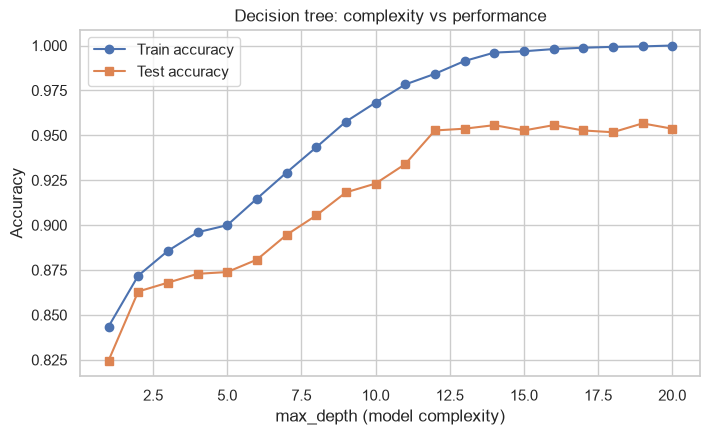

Best test accuracy at depth 19 -> 0.9567


In [ ]:
# Sweep the depth to see the whole bias-variance picture
depths = range(1, 21)
tr_scores, te_scores = [], []
for d in depths:
    m = make_pipe(DecisionTreeClassifier(max_depth=d, random_state=SEED)).fit(X_train, y_train)
    tr_scores.append(m.score(X_train, y_train))
    te_scores.append(m.score(X_test, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, tr_scores, marker="o", label="Train accuracy")
plt.plot(depths, te_scores, marker="s", label="Test accuracy")
plt.xlabel("max_depth (model complexity)"); plt.ylabel("Accuracy")
plt.title("Decision tree: complexity vs performance"); plt.legend(); plt.show()
best_d = list(depths)[int(np.argmax(te_scores))]
print("Best test accuracy at depth", best_d, "->", round(max(te_scores), 4))

**Reading the results:** the depth-1 stump scores low on *both* train and test (and its recall for churners is poor): it is too simple to capture the pattern, so it **underfits** (high bias). The unlimited tree gets ~100% on train but a clearly lower score on test: it memorised the training data, so it **overfits** (high variance). Somewhere in the middle the test score peaks.

**Analytical Question 1 – bias and variance as complexity increases**
As the model gets more complex, **bias goes down** (the model can represent more complicated patterns, so its systematic error shrinks) while **variance goes up** (it becomes more sensitive to the particular training sample, so it starts fitting noise). The total test error is U-shaped: very simple models are dominated by bias, very complex ones by variance, and the goal is to find the sweet spot between them.

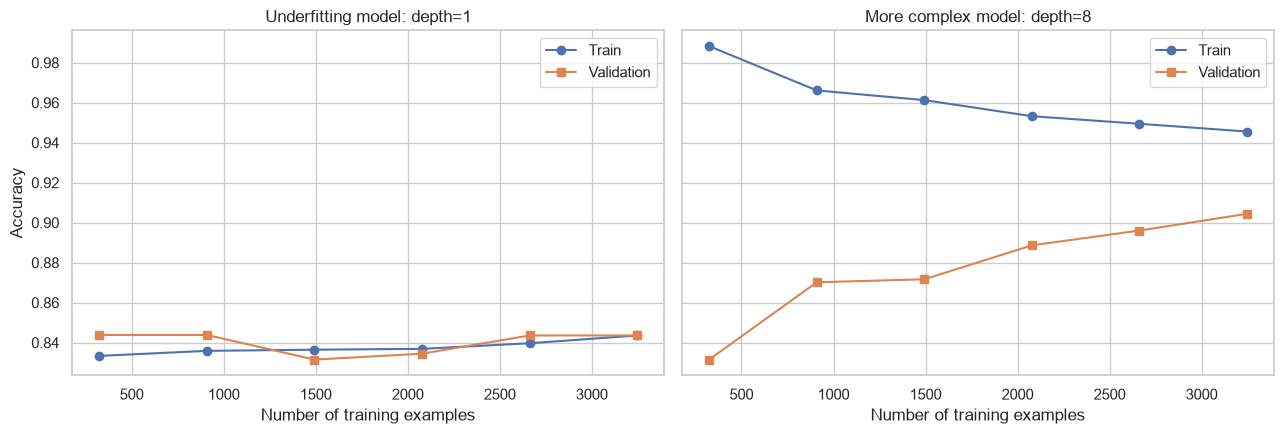

In [ ]:
sizes = np.linspace(0.1, 1.0, 6)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (label, depth) in zip(axes, [("Underfitting model: depth=1", 1), ("More complex model: depth=8", 8)]):
    sz, tr, va = learning_curve(
        make_pipe(DecisionTreeClassifier(max_depth=depth, random_state=SEED)),
        X_train, y_train, train_sizes=sizes, cv=5, scoring="accuracy", n_jobs=-1)
    ax.plot(sz, tr.mean(axis=1), marker="o", label="Train")
    ax.plot(sz, va.mean(axis=1), marker="s", label="Validation")
    ax.set_title(label); ax.set_xlabel("Number of training examples"); ax.legend()
axes[0].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

**Analytical Question 2 – why complexity helps an underfitting model but more data doesn't**

Look at the left plot (depth=1). Train and validation curves are already close to each other and **both plateau at a low value**. The problem is not a lack of examples; the model family itself (one single split) is too weak to describe the data, so it makes the same systematic mistakes no matter how many rows it sees. Adding more rows just gives it more data to be equally wrong about: the curves stay flat.

In the right plot, the deeper tree reaches a clearly higher level, because we gave the model enough **capacity** to represent the real decision boundary (interactions between tenure, complaints, cashback, etc.). That lowers the bias. So for underfitting, fix the model (more complexity, more/better features, less regularization); more data is the cure for **overfitting / high variance**, not for high bias.

### 3.2 Regularization & shrinkage: Logistic Regression
Three penalties on the scaled features (`solver="saga"`, `max_iter=2000`). `C=1.0` is used for all of them so that the comparison is only about the *type* of penalty.
- **L2 (Ridge):** shrinks all coefficients towards zero but rarely makes them exactly zero.
- **L1 (Lasso):** can push some coefficients to exactly zero, so it does feature selection.
- **Elastic Net:** a mix of both (`l1_ratio=0.5`).

In [ ]:
warnings.filterwarnings("ignore", category=FutureWarning)   # newer sklearn warns about 'penalty'
warnings.filterwarnings("ignore", message=".*penalty.*")

lr_configs = {
    "LogReg L2 (Ridge)":       dict(penalty="l2"),
    "LogReg L1 (Lasso)":       dict(penalty="l1"),
    "LogReg ElasticNet (0.5)": dict(penalty="elasticnet", l1_ratio=0.5),
}

lr_models, lr_rows = {}, []
for name, kw in lr_configs.items():
    clf = LogisticRegression(solver="saga", max_iter=2000, random_state=SEED, **kw)
    pipe = make_pipe(clf).fit(X_train, y_train)
    lr_models[name] = pipe
    row = evaluate(pipe, name)
    coefs = pipe.named_steps["clf"].coef_.ravel()
    row["n_features"] = coefs.size
    row["zero_coefs"] = int(np.sum(coefs == 0))
    row["mean_abs_coef"] = np.abs(coefs).mean()
    lr_rows.append(row)

pd.DataFrame(lr_rows).set_index("model").round(4)

,train_acc,test_acc,precision,recall,f1,n_features,zero_coefs,mean_abs_coef
model,,,,,,,,
LogReg L2 (Ridge),0.8918,0.8847,0.7742,0.4286,0.5517,30,0,1.0970
LogReg L1 (Lasso),0.8953,0.8877,0.7455,0.4881,0.5899,30,3,1.3888
LogReg ElasticNet (0.5),0.8938,0.8857,0.7653,0.4464,0.5639,30,4,1.1830


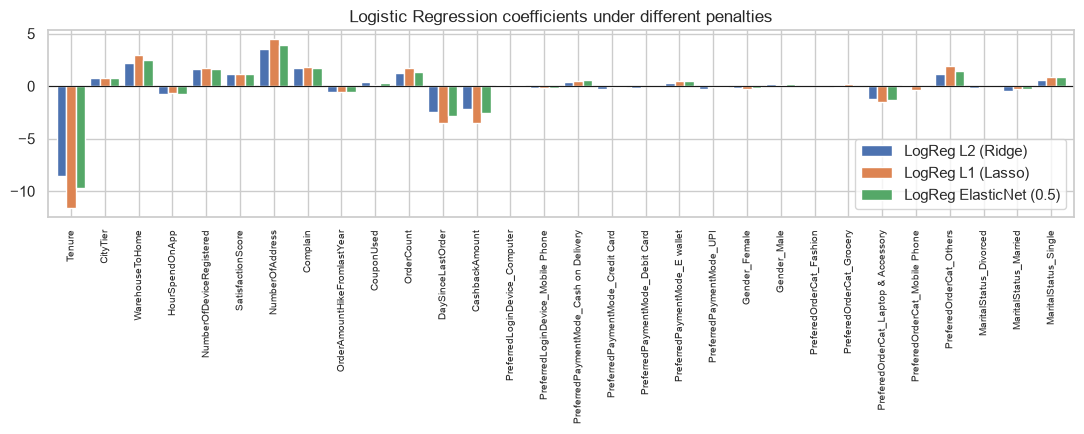

Top 8 features by |coef| (L2 model):
num__Tenure                      8.535
num__NumberOfAddress             3.492
num__DaySinceLastOrder           2.450
num__WarehouseToHome             2.248
num__CashbackAmount              2.197
num__Complain                    1.696
num__NumberOfDeviceRegistered    1.596
num__OrderCount                  1.218


In [ ]:
# Visualise shrinkage: coefficient size per penalty
feat_names = lr_models["LogReg L2 (Ridge)"].named_steps["prep"].get_feature_names_out()
coef_df = pd.DataFrame({n: m.named_steps["clf"].coef_.ravel() for n, m in lr_models.items()}, index=feat_names)

fig, ax = plt.subplots(figsize=(11, 4.5))
coef_df.plot(kind="bar", ax=ax, width=0.85)
ax.set_title("Logistic Regression coefficients under different penalties")
ax.set_xticks(range(len(feat_names)))
ax.set_xticklabels([n.replace("num__", "").replace("cat__", "") for n in feat_names], fontsize=7)
ax.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

print("Top 8 features by |coef| (L2 model):")
print(coef_df["LogReg L2 (Ridge)"].abs().sort_values(ascending=False).head(8).round(3).to_string())

**Discussion:** the three models reach very similar scores, which makes sense because with `C=1` and only ~30 features the penalties are mild. The difference shows up in the coefficients: **L2** keeps every feature with a small weight, **L1** sets some of them to exactly zero (a sparse model, see the `zero_coefs` column), and **Elastic Net** sits in between. If I needed a simpler/more interpretable model I would go with L1 or Elastic Net; with many correlated features Elastic Net is usually the safer choice because L1 alone tends to pick one feature from a correlated group and ignore the rest. A stronger penalty (smaller `C`) would increase the shrinkage and the bias, but lower the variance.

---
# Part 4: Ensemble Learning
### 4.1 Bagging vs Pasting + Out-of-Bag evaluation
Both ensembles use 200 decision trees, each trained on 80% of the rows (`max_samples=0.8`). The only difference is **bootstrap**: sampling *with* replacement (bagging) or *without* (pasting).

> Note: with `bootstrap=False` and the default `max_samples=1.0` every tree would see exactly the same full dataset and all 200 trees would be identical, so pasting would be pointless. That's why I used `max_samples=0.8` for both models, to make the comparison fair and meaningful.

In [ ]:
bag = make_pipe(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=SEED),
    n_estimators=200, max_samples=0.8,
    bootstrap=True, oob_score=True, n_jobs=-1, random_state=SEED
)).fit(X_train, y_train)

paste = make_pipe(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=SEED),
    n_estimators=200, max_samples=0.8,
    bootstrap=False, n_jobs=-1, random_state=SEED
)).fit(X_train, y_train)

evaluate(bag, "Bagging (bootstrap=True)")
evaluate(paste, "Pasting (bootstrap=False)")

oob = bag.named_steps["clf"].oob_score_
bag_test = accuracy_score(y_test, bag.predict(X_test))
print("OOB score (Bagging)  : %.4f" % oob)
print("Test accuracy (Bagging): %.4f" % bag_test)
print("Difference           : %.4f" % abs(oob - bag_test))
pd.DataFrame(results[-2:]).set_index("model").round(4)

OOB score (Bagging)  : 0.9576
Test accuracy (Bagging): 0.9665
Difference           : 0.0089


,train_acc,test_acc,precision,recall,f1
model,,,,,
Bagging (bootstrap=True),0.9998,0.9665,0.9467,0.8452,0.8931
Pasting (bootstrap=False),1.0000,0.9685,0.9304,0.8750,0.9018


**Analytical Questions**

**1. What does `n_jobs=-1` do?**
It tells scikit-learn to use **all available CPU cores** to run the work in parallel. In `BaggingClassifier` the trees are independent from each other, so training them on several cores at once makes `fit` (and `predict`) much faster. The results don't change, only the speed.

**2. Which technique is used when `bootstrap=False`?**
**Pasting**: each predictor is trained on a random subset of the training set sampled **without replacement**. (With `bootstrap=True` it's Bagging: sampling **with** replacement.)

**3. OOB score vs test accuracy, and the advantage of OOB**
The OOB score printed above is very close to the test accuracy, which shows it's an honest estimate of how the ensemble generalises. It works like this: with bootstrap sampling, each tree is trained on a sample, and the rows it did *not* see (roughly 37% when sampling the full size, even more here with 80%) are "out-of-bag" for that tree. Each training row is then predicted only by the trees that never saw it, and those predictions are scored. The **main advantage** is that you get a validation-style estimate **for free**, without holding out a separate validation set or running cross-validation, so all the data can be used for training. (The small gap between the two numbers is normal: OOB uses only a part of the trees for each row, and the test set is a finite random sample.)

### 4.2 Boosting: AdaBoost

In [ ]:
ada = make_pipe(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
    n_estimators=200, learning_rate=0.5, random_state=SEED
)).fit(X_train, y_train)

row = evaluate(ada, "AdaBoost")
print("AdaBoost  ->  Accuracy: %.4f | Precision: %.4f | Recall: %.4f | F1: %.4f"
      % (row["test_acc"], row["precision"], row["recall"], row["f1"]))

AdaBoost  ->  Accuracy: 0.8818 | Precision: 0.7182 | Recall: 0.4702 | F1: 0.5683


In [ ]:
# Tiny numeric demo of the AdaBoost weight update (one round, 10 samples, 2 mistakes)
w = np.full(10, 0.1)
wrong = np.array([0, 0, 1, 0, 0, 0, 1, 0, 0, 0], dtype=bool)

err = w[wrong].sum() / w.sum()            # weighted error of the weak learner
alpha = 0.5 * np.log((1 - err) / err)     # learner's "say" in the final vote
w_new = w * np.exp(np.where(wrong, alpha, -alpha))
w_new /= w_new.sum()                      # re-normalise

print("weighted error: %.2f | alpha: %.3f" % (err, alpha))
print("weights before :", w.round(3))
print("weights after  :", w_new.round(3))

weighted error: 0.20 | alpha: 0.693
weights before : [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
weights after  : [0.062 0.062 0.25  0.062 0.062 0.062 0.25  0.062 0.062 0.062]


**Analytical Question – what happens to the weights of misclassified instances in AdaBoost, and why?**

After each iteration the weights of the **misclassified instances are increased** and the weights of the correctly classified ones are decreased (the demo above shows 0.1 → ~0.25 for the two mistakes, and ~0.06 for the rest), then all weights are re-normalised to sum to 1. The update uses the weak learner's weight `alpha = ½·ln((1−err)/err)`.

**Why:** AdaBoost wants each new weak learner to concentrate on what the previous ones got wrong. The hard cases get more weight, so the next learner is forced to pay attention to them (its weighted error counts them much more). Over many rounds the ensemble builds a weighted vote of many simple learners, where each learner's vote is bigger if it was more accurate. This mainly reduces **bias**, which is why shallow stumps (high bias) work well as base learners. The downside is that very noisy samples/outliers also get more and more weight.

### 4.3 Voting: hard vs soft

In [ ]:
estimators = [
    ("lr",  LogisticRegression(max_iter=2000, random_state=SEED)),
    ("rf",  RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
    ("svc", SVC(probability=True, random_state=SEED)),
]

hard_vote = make_pipe(VotingClassifier(estimators, voting="hard")).fit(X_train, y_train)
soft_vote = make_pipe(VotingClassifier(estimators, voting="soft")).fit(X_train, y_train)

# individual members for reference (same preprocessing)
singles = {}
for name, est in estimators:
    from sklearn.base import clone
    singles[name] = make_pipe(clone(est)).fit(X_train, y_train)

rows = [evaluate(m, f"Single: {n.upper()}", store=False) for n, m in singles.items()]
rows.append(evaluate(hard_vote, "Voting (hard)"))
rows.append(evaluate(soft_vote, "Voting (soft)"))
pd.DataFrame(rows).set_index("model").round(4)

,train_acc,test_acc,precision,recall,f1
model,,,,,
Single: LR,0.8921,0.8847,0.7742,0.4286,0.5517
Single: RF,1.0000,0.9685,0.9595,0.8452,0.8987
Single: SVC,0.9012,0.8857,0.8333,0.3869,0.5285
Voting (hard),0.9187,0.9015,0.8953,0.4583,0.6063
Voting (soft),0.9441,0.9074,0.8627,0.5238,0.6519


**Hard vs soft voting:**
- **Hard voting** takes the *majority class label* predicted by the three models (each model gets one vote).
- **Soft voting** *averages the predicted probabilities* and picks the class with the highest average. This is why `SVC` needs `probability=True`: it has to output probabilities.

Soft voting usually does a little better when the models are well calibrated, because a very confident model counts more than a hesitant one, and hard voting throws that information away. Check the table above: compare each voting model with its best single member. When one model (here the Random Forest) is clearly stronger than the others, the ensemble doesn't always beat it, since voting helps most when the members are **diverse and similarly good**.

---
# Part 5: Final Comparison & Conclusions

,train_acc,test_acc,precision,recall,f1,n_features,zero_coefs,mean_abs_coef
model,,,,,,,,
Pasting (bootstrap=False),1.0000,0.9685,0.9304,0.8750,0.9018,NaN,NaN,NaN
Bagging (bootstrap=True),0.9998,0.9665,0.9467,0.8452,0.8931,NaN,NaN,NaN
Tree unlimited (high var),1.0000,0.9537,0.8497,0.8750,0.8622,NaN,NaN,NaN
Voting (soft),0.9441,0.9074,0.8627,0.5238,0.6519,NaN,NaN,NaN
Voting (hard),0.9187,0.9015,0.8953,0.4583,0.6063,NaN,NaN,NaN
LogReg L1 (Lasso),0.8953,0.8877,0.7455,0.4881,0.5899,30.0,3.0,1.3888
AdaBoost,0.8978,0.8818,0.7182,0.4702,0.5683,NaN,NaN,NaN
LogReg ElasticNet (0.5),0.8938,0.8857,0.7653,0.4464,0.5639,30.0,4.0,1.1830
LogReg L2 (Ridge),0.8918,0.8847,0.7742,0.4286,0.5517,30.0,0.0,1.0970


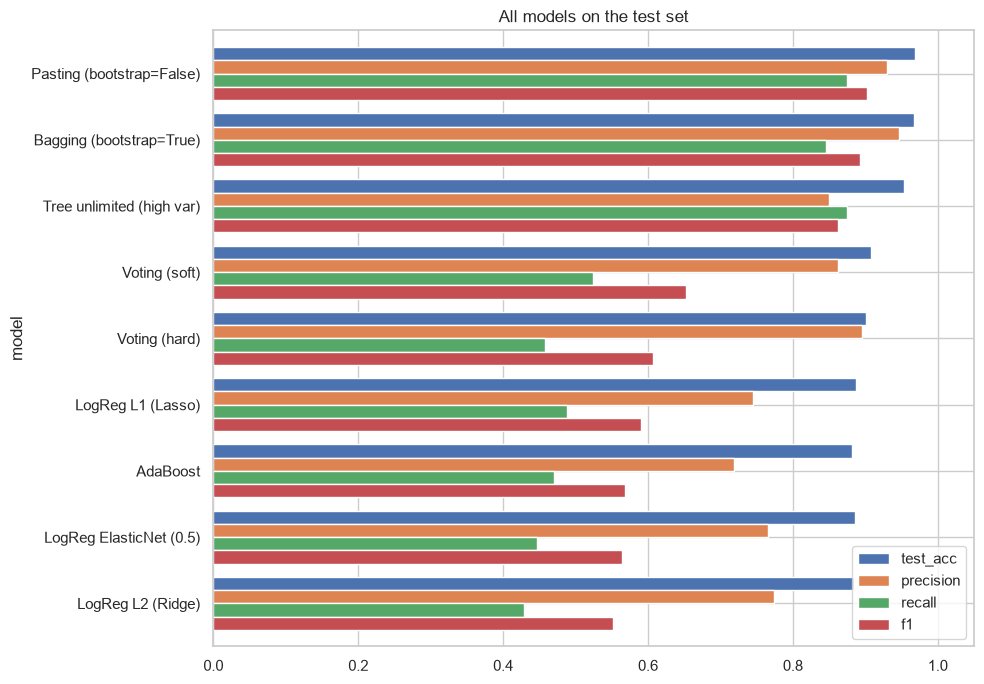

In [ ]:
final = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model")
final = final.sort_values("f1", ascending=False)
display(final.round(4))

ax = final[["test_acc", "precision", "recall", "f1"]].plot(kind="barh", figsize=(10, 7), width=0.8)
ax.invert_yaxis(); ax.set_xlim(0, 1.05); ax.set_title("All models on the test set")
plt.tight_layout(); plt.show()

### Conclusions
- **Data:** churn is imbalanced (~17%), so accuracy alone hides how well we catch churners; F1 and Recall matter more for the business case (a missed churner = a lost customer).
- **Pipeline:** putting the imputer, scaler and encoder inside a `ColumnTransformer` + `Pipeline` means everything is learned on the training data only, so the test results are trustworthy.
- **Bias-variance:** a stump underfits, an unlimited tree overfits; more data does not fix underfitting, more capacity does.
- **Regularization:** L1/L2/Elastic Net gave almost the same performance here, but L1 and Elastic Net produce sparser, easier-to-interpret models.
- **Ensembles:** tree-based ensembles (Bagging, Random Forest inside the vote, AdaBoost) are clearly better than the linear model at catching churners, because the churn relationship is non-linear. OOB gave a free and reliable performance estimate.
- **Possible next steps:** tune hyperparameters with `GridSearchCV`/`RandomizedSearchCV`, handle the imbalance (`class_weight="balanced"` or threshold tuning), and try gradient boosting.